In [2]:
# Cell 1: Install required packages
!pip -q install \
    datasets \
    sentence-transformers \
    faiss-cpu \
    transformers \
    accelerate \
    pandas \
    numpy \
    scikit-learn \
    scipy \
    matplotlib \
    seaborn \
    tqdm

In [3]:
# Cell 2: Imports
import os
import re
import time
import random
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import faiss
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import matplotlib.pyplot as plt
import torch

print("Imports done.")

Imports done.


In [4]:
# Cell 3: Central configuration

CONFIG = {
    # Dataset
    "dataset": "squad",

    # Models
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
    "llm": "google/flan-t5-small",

    # Chunking
    "fixed_chunk_size": 128,
    "fixed_chunk_overlap": 20,
    "adaptive_max_tokens": 128,

    # Retrieval
    "top_k": 5,

    # Filtering
    "filter_threshold": 0.35,

    # Experiment
    "max_questions": 300,
    "seed": 42,

    # Generation
    "llm_max_new_tokens": 64,
}

print("CONFIG:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

CONFIG:
  dataset: squad
  embedding_model: sentence-transformers/all-MiniLM-L6-v2
  llm: google/flan-t5-small
  fixed_chunk_size: 128
  fixed_chunk_overlap: 20
  adaptive_max_tokens: 128
  top_k: 5
  filter_threshold: 0.35
  max_questions: 300
  seed: 42
  llm_max_new_tokens: 64


In [5]:
# Cell 4: Set random seeds
SEED = CONFIG["seed"]
random.seed(SEED)
np.random.seed(SEED)
print("Random seed:", SEED)

Random seed: 42


In [6]:
# Cell 5: Dataset loader with per-dataset configs

DATASET_CONFIGS = {
    "squad": {
        "name": "rajpurkar/squad",
        "train_split": "train",
        "eval_split": "validation",
        "question_field": "question",
    }
}

ds_cfg = DATASET_CONFIGS[CONFIG["dataset"]]

dataset = load_dataset(
    ds_cfg["name"]
)

train_data = dataset[
    ds_cfg["train_split"]
]

validation_data = dataset[
    ds_cfg["eval_split"]
]

print("Dataset:", CONFIG["dataset"])
print("Training examples:", len(train_data))
print("Validation examples:", len(validation_data))

README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

Dataset: squad
Training examples: 87599
Validation examples: 10570


In [7]:
# Cell 6: Inspect a sample

sample = validation_data[0]

print("ID:", sample["id"])

print("\nQuestion:")
print(sample["question"])

print("\nContext:")
print(sample["context"][:300], "...")

print("\nAnswer:")
print(sample["answers"])

ID: 56be4db0acb8001400a502ec

Question:
Which NFL team represented the AFC at Super Bowl 50?

Context:
Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super B ...

Answer:
{'text': ['Denver Broncos', 'Denver Broncos', 'Denver Broncos'], 'answer_start': [177, 177, 177]}


In [8]:
# Cell 7: Build unique documents with IDs

def extract_context(item):
    """Return the raw context string from a dataset item."""

    if CONFIG["dataset"] == "squad":
        return item["context"].strip()

    raise ValueError(
        f"No context extractor for {CONFIG['dataset']}"
    )


documents = {}

for item in validation_data:

    ctx = extract_context(item)

    if ctx not in documents:

        documents[ctx] = {
            "text": ctx,
            "id": len(documents)
        }


documents = list(documents.values())

print(
    "Unique documents:",
    len(documents)
)

Unique documents: 2067


In [9]:
# Cell 8: Select evaluation questions
MAX_QUESTIONS = CONFIG["max_questions"]

eval_data = validation_data.shuffle(seed=SEED).select(
    range(min(MAX_QUESTIONS, len(validation_data)))
)

print("Evaluation questions:", len(eval_data))

Evaluation questions: 300


In [10]:
# Cell 9: Load embedding model
EMBEDDING_MODEL_NAME = CONFIG["embedding_model"]
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
print("Embedding model loaded:", EMBEDDING_MODEL_NAME)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded: sentence-transformers/all-MiniLM-L6-v2


In [11]:
# Cell 10: Load tokenizer for chunking
chunk_tokenizer = AutoTokenizer.from_pretrained(
    CONFIG["embedding_model"]
)
print("Chunk tokenizer loaded.")

Chunk tokenizer loaded.


In [12]:
# Cell 11: Fixed-size chunking
def fixed_chunk(text, size=None, overlap=None):
    if size is None:
        size = CONFIG["fixed_chunk_size"]
    if overlap is None:
        overlap = CONFIG["fixed_chunk_overlap"]

    tokens = chunk_tokenizer.encode(text, add_special_tokens=False)
    chunks = []
    step = size - overlap

    for i in range(0, len(tokens), step):
        chunk_tokens = tokens[i:i + size]
        if len(chunk_tokens) == 0:
            continue
        chunk_text = chunk_tokenizer.decode(
            chunk_tokens, skip_special_tokens=True
        )
        chunks.append(chunk_text)

    return chunks

In [13]:
# Cell 12: Test fixed chunking
test_text = documents[0]["text"]
chunks = fixed_chunk(test_text)

print("Original text length:", len(test_text))
print("Number of chunks:", len(chunks))
for i, chunk in enumerate(chunks[:2]):
    print(f"\nChunk {i+1}:\n{chunk[:300]}...")

Original text length: 775
Number of chunks: 2

Chunk 1:
super bowl 50 was an american football game to determine the champion of the national football league ( nfl ) for the 2015 season. the american football conference ( afc ) champion denver broncos defeated the national football conference ( nfc ) champion carolina panthers 24 – 10 to earn their third...

Chunk 2:
well as temporarily suspending the tradition of naming each super bowl game with roman numerals ( under which the game would have been known as " super bowl l " ), so that the logo could prominently feature the arabic numerals 50....


In [14]:
# Cell 13: Sentence splitter
def split_sentences(text):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in sentences if s.strip()]

In [15]:
# Cell 14: Adaptive chunking
def count_tokens(text):
    return len(chunk_tokenizer.encode(text, add_special_tokens=False))


def adaptive_chunk(text, max_tokens=None):
    if max_tokens is None:
        max_tokens = CONFIG["adaptive_max_tokens"]

    paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
    chunks = []

    for paragraph in paragraphs:
        paragraph_tokens = count_tokens(paragraph)

        if paragraph_tokens <= max_tokens:
            chunks.append(paragraph)
            continue

        sentences = split_sentences(paragraph)
        current_chunk = ""

        for sentence in sentences:
            candidate = (current_chunk + " " + sentence).strip()

            if count_tokens(candidate) <= max_tokens:
                current_chunk = candidate
            else:
                if current_chunk:
                    chunks.append(current_chunk)

                if count_tokens(sentence) > max_tokens:
                    sentence_chunks = fixed_chunk(
                        sentence, size=max_tokens, overlap=0
                    )
                    chunks.extend(sentence_chunks)
                    current_chunk = ""
                else:
                    current_chunk = sentence

        if current_chunk:
            chunks.append(current_chunk)

    return chunks

In [16]:
# Cell 15: Compare chunking methods
text = documents[0]["text"]
fixed_chunks = fixed_chunk(text)
adaptive_chunks = adaptive_chunk(text)

print("Fixed chunks:", len(fixed_chunks))
print("Adaptive chunks:", len(adaptive_chunks))

print("\n--- FIXED ---")
for i, chunk in enumerate(fixed_chunks[:2]):
    print(f"\n{i+1}. {chunk[:250]}...")

print("\n--- ADAPTIVE ---")
for i, chunk in enumerate(adaptive_chunks[:2]):
    print(f"\n{i+1}. {chunk[:250]}...")

Fixed chunks: 2
Adaptive chunks: 2

--- FIXED ---

1. super bowl 50 was an american football game to determine the champion of the national football league ( nfl ) for the 2015 season. the american football conference ( afc ) champion denver broncos defeated the national football conference ( nfc ) cham...

2. well as temporarily suspending the tradition of naming each super bowl game with roman numerals ( under which the game would have been known as " super bowl l " ), so that the logo could prominently feature the arabic numerals 50....

--- ADAPTIVE ---

1. Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion C...

2. As this was the 50th Super Bowl, the league emphasized the "golden anniversary" with various gold-themed initiatives, as well as temporarily suspending the tradition of namin

In [17]:
# Cell 16: Build all chunks
def build_chunks(documents, method):
    all_chunks = []
    for doc in tqdm(documents, desc=f"Creating {method} chunks"):
        text = doc["text"]

        if method == "fixed":
            chunks = fixed_chunk(text)
        elif method == "adaptive":
            chunks = adaptive_chunk(text)
        else:
            raise ValueError("Unknown chunking method")

        for chunk in chunks:
            all_chunks.append({
                "chunk_id": len(all_chunks),
                "document_id": doc["id"],
                "text": chunk
            })
    return all_chunks

In [18]:
# Cell 17: Build fixed chunks
fixed_chunks = build_chunks(documents, "fixed")
print("Total fixed chunks:", len(fixed_chunks))

Creating fixed chunks:   0%|          | 0/2067 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (617 > 512). Running this sequence through the model will result in indexing errors


Total fixed chunks: 4155


In [19]:
# Cell 18: Build adaptive chunks
adaptive_chunks = build_chunks(documents, "adaptive")
print("Total adaptive chunks:", len(adaptive_chunks))

Creating adaptive chunks:   0%|          | 0/2067 [00:00<?, ?it/s]

Total adaptive chunks: 3718


In [20]:
# Cell 19: Preview
fixed_df = pd.DataFrame(fixed_chunks)
adaptive_df = pd.DataFrame(adaptive_chunks)
display(fixed_df.head())
display(adaptive_df.head())

,chunk_id,document_id,text
0,0,0,super bowl 50 was an american football game to...
1,1,0,well as temporarily suspending the tradition o...
2,2,1,the panthers finished the regular season with ...
3,3,1,pittsburgh steelers as one of four teams that ...
4,4,2,the broncos took an early lead in super bowl 5...


,chunk_id,document_id,text
0,0,0,Super Bowl 50 was an American football game to...
1,1,0,"As this was the 50th Super Bowl, the league em..."
2,2,1,The Panthers finished the regular season with ...
3,3,2,The Broncos took an early lead in Super Bowl 5...
4,4,3,"CBS broadcast Super Bowl 50 in the U.S., and c..."


In [21]:
# Cell 20: Create embeddings
def create_embeddings(chunks):
    texts = [item["text"] for item in chunks]
    embeddings = embedding_model.encode(
        texts,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    return np.asarray(embeddings, dtype="float32")

In [22]:
# Cell 21: Embed fixed chunks
fixed_embeddings = create_embeddings(fixed_chunks)
print("Fixed embedding shape:", fixed_embeddings.shape)

Batches:   0%|          | 0/65 [00:00<?, ?it/s]

Fixed embedding shape: (4155, 384)


In [23]:
# Cell 22: Embed adaptive chunks
adaptive_embeddings = create_embeddings(adaptive_chunks)
print("Adaptive embedding shape:", adaptive_embeddings.shape)

Batches:   0%|          | 0/59 [00:00<?, ?it/s]

Adaptive embedding shape: (3718, 384)


In [24]:
# Cell 23: Build FAISS indexes
dimension = fixed_embeddings.shape[1]

fixed_index = faiss.IndexFlatIP(dimension)
adaptive_index = faiss.IndexFlatIP(dimension)

fixed_index.add(fixed_embeddings)
adaptive_index.add(adaptive_embeddings)

print("Fixed index:", fixed_index.ntotal)
print("Adaptive index:", adaptive_index.ntotal)

Fixed index: 4155
Adaptive index: 3718


In [25]:
# Cell 24: Embed a single query
def embed_query(question):
    embedding = embedding_model.encode(
        [question], normalize_embeddings=True
    )
    return np.asarray(embedding, dtype="float32")

In [26]:
# Cell 25: Retrieval function
def retrieve(question, index, chunks, k=None):
    if k is None:
        k = CONFIG["top_k"]

    query_embedding = embed_query(question)
    scores, indices = index.search(query_embedding, k)

    results = []
    for score, idx in zip(scores[0], indices[0]):
        results.append({
            "chunk_id": int(idx),
            "score": float(score),
            "text": chunks[idx]["text"],
            "document_id": chunks[idx]["document_id"]
        })
    return results

In [27]:
# Cell 26: Test retrieval
question = eval_data[0]["question"]
results = retrieve(question, fixed_index, fixed_chunks)

print("Question:", question)
for i, r in enumerate(results):
    print(f"\n[Rank {i+1}] score={r['score']:.4f}")
    print(r["text"][:250], "...")

Question: In what year did Massachusetts first require children to be educated in schools?

[Rank 1] score=0.6171
private schooling in the united states has been debated by educators, lawmakers and parents, since the beginnings of compulsory education in massachusetts in 1852. the supreme court precedent appears to favor educational choice, so long as states may ...

[Rank 2] score=0.5212
of upper secondary, and three years of university. all schools had a common curriculum. ...

[Rank 3] score=0.4909
in the early years the college trained many puritan ministers. [ citation needed ] ( a 1643 publication said the school ' s purpose was " to advance learning and perpetuate it to posterity, dreading to leave an illiterate ministry to the churches whe ...

[Rank 4] score=0.4830
during the mass high school education movement from 1910 – 1940, there was an increase in skilled workers, which led to a decrease in the price of skilled labor. high school education during the period was designed 

In [28]:
# Cell 27: Context filtering
def filter_chunks(question, retrieved_chunks, threshold=None):
    if threshold is None:
        threshold = CONFIG["filter_threshold"]
    return [c for c in retrieved_chunks if c["score"] >= threshold]

In [29]:
# Cell 28: Test filtering
filtered_results = filter_chunks(question, results)
print("Retrieved:", len(results))
print("After filtering:", len(filtered_results))

Retrieved: 5
After filtering: 5


In [30]:
# Cell 29: Load LLM (seq2seq)
LLM_NAME = CONFIG["llm"]
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm_model = AutoModelForSeq2SeqLM.from_pretrained(
    LLM_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
)

if torch.cuda.is_available():
    llm_model = llm_model.cuda()

print("LLM loaded:", LLM_NAME)
print("GPU available:", torch.cuda.is_available())

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

LLM loaded: google/flan-t5-small
GPU available: True


In [31]:
# Cell 30: Generator function (seq2seq)
def generator(prompt):
    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    )

    if torch.cuda.is_available():
        inputs = {k: v.cuda() for k, v in inputs.items()}

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=CONFIG["llm_max_new_tokens"],
            do_sample=False
        )

    answer = llm_tokenizer.decode(outputs[0], skip_special_tokens=True).strip()

    return [{"generated_text": answer}]

print("Generator ready.")

Generator ready.


In [32]:
# Cell 31: Build prompt
def create_prompt(question, chunks):
    context = "\n\n".join(
        f"Context {i+1}: {c['text']}"
        for i, c in enumerate(chunks)
    )
    return f"""Answer the question using only the provided context.

If the answer cannot be found in the context, say: "I don't know."

Context:
{context}

Question:
{question}

Answer:
"""

In [33]:
# Cell 32: Generate answer with accurate GPU timing

def generate_answer(question, chunks):
    prompt = create_prompt(question, chunks)

    # Synchronize GPU before starting timer
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.time()

    output = generator(prompt)

    # Synchronize GPU before stopping timer
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    response_time = time.time() - start

    return output[0]["generated_text"], response_time, prompt

In [34]:
# Cell 33: Test generation
answer, rt, prompt = generate_answer(question, filtered_results)
print("Question:", question)
print("\nAnswer:", answer)
print("\nResponse time:", round(rt, 3), "s")

Question: In what year did Massachusetts first require children to be educated in schools?

Answer: 1940

Response time: 0.713 s


In [35]:
# Cell 34: Count actual LLM input tokens

def count_prompt_tokens(prompt):
    inputs = llm_tokenizer(
        prompt,
        truncation=True,
        max_length=1024,
        add_special_tokens=True
    )

    return len(inputs["input_ids"])

In [36]:
# Cell 35: Normalize + Exact Match

def normalize_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def exact_match(prediction, ground_truth):

    # Support multiple valid reference answers
    if isinstance(ground_truth, str):
        ground_truth = [ground_truth]

    scores = []

    for answer in ground_truth:
        score = int(
            normalize_text(prediction) ==
            normalize_text(answer)
        )
        scores.append(score)

    return max(scores) if scores else 0

In [37]:
# Cell 36: Proper token-level F1 score

from collections import Counter


def f1_score(prediction, ground_truth):

    # Support multiple valid reference answers
    if isinstance(ground_truth, str):
        ground_truth = [ground_truth]

    best_f1 = 0.0

    for answer in ground_truth:

        pred_tokens = normalize_text(
            prediction
        ).split()

        truth_tokens = normalize_text(
            answer
        ).split()

        if not pred_tokens and not truth_tokens:
            current_f1 = 1.0

        elif not pred_tokens or not truth_tokens:
            current_f1 = 0.0

        else:
            common = (
                Counter(pred_tokens) &
                Counter(truth_tokens)
            )

            num_common = sum(common.values())

            if num_common == 0:
                current_f1 = 0.0

            else:
                precision = num_common / len(pred_tokens)
                recall = num_common / len(truth_tokens)

                current_f1 = (
                    2 * precision * recall /
                    (precision + recall)
                )

        best_f1 = max(best_f1, current_f1)

    return best_f1

In [38]:
# Cell 37: Faithfulness proxy
#
# This is a lightweight lexical-overlap proxy.
# It is NOT the full RAGAS faithfulness metric.

def faithfulness_score(answer, chunks):

    answer_tokens = set(
        normalize_text(answer).split()
    )

    context = " ".join(
        c["text"]
        for c in chunks
    )

    context_tokens = set(
        normalize_text(context).split()
    )

    if not answer_tokens:
        return 0.0

    supported_tokens = (
        answer_tokens &
        context_tokens
    )

    return (
        len(supported_tokens) /
        len(answer_tokens)
    )

In [39]:
# Cell 38: Retrieval Hit@K / Recall@K

def retrieval_metrics(
    retrieved_chunks,
    gold_document_id
):

    retrieved_ids = {
        c["document_id"]
        for c in retrieved_chunks
    }

    # For SQuAD there is one gold document
    hit = (
        gold_document_id
        in retrieved_ids
    )

    return int(hit)

In [40]:
# Cell 39: Full RAG pipeline

def run_pipeline(
    question,
    gold_answer,
    gold_document_id,
    index,
    chunks,
    use_filter=False,
    filter_threshold=None
):

    # Start total timing
    total_start = time.time()


    # --------------------------------------------------
    # 1. Retrieve top-k chunks
    # --------------------------------------------------

    retrieved = retrieve(
        question,
        index,
        chunks
    )


    # --------------------------------------------------
    # 2. Optional context filtering
    # --------------------------------------------------

    if use_filter:

        final_chunks = filter_chunks(
            question,
            retrieved,
            threshold=filter_threshold
        )

    else:

        final_chunks = retrieved


    # --------------------------------------------------
    # 3. Safety fallback
    # --------------------------------------------------

    if len(final_chunks) == 0:

        final_chunks = retrieved[:1]


    # --------------------------------------------------
    # 4. Generate answer
    # --------------------------------------------------

    answer, generation_time, prompt = (
        generate_answer(
            question,
            final_chunks
        )
    )


    # --------------------------------------------------
    # 5. Total response time
    # --------------------------------------------------

    total_time = (
        time.time() -
        total_start
    )


    # --------------------------------------------------
    # 6. Evaluation metrics
    # --------------------------------------------------

    return {

        "question": question,

        "gold_answer": gold_answer,

        "answer": answer,

        "exact_match": exact_match(
            answer,
            gold_answer
        ),

        "f1": f1_score(
            answer,
            gold_answer
        ),

        "faithfulness": faithfulness_score(
            answer,
            final_chunks
        ),

        "retrieval_hit": retrieval_metrics(
            retrieved,
            gold_document_id
        ),

        "tokens": count_prompt_tokens(
            prompt
        ),

        "response_time": total_time,

        "retrieved_chunks": len(
            retrieved
        ),

        "final_chunks": len(
            final_chunks
        )
    }

In [41]:
# Cell 40: Prepare experiment questions

def extract_answers(item):

    if CONFIG["dataset"] == "squad":

        answers = item["answers"]["text"]

        # Return all valid reference answers
        return answers if answers else [""]

    raise ValueError(
        f"No answer extractor for {CONFIG['dataset']}"
    )


# Map document text to document ID
context_to_id = {
    d["text"]: d["id"]
    for d in documents
}


experiment_questions = []

for item in eval_data:

    ctx = extract_context(item)

    if ctx not in context_to_id:
        continue

    experiment_questions.append({

        "question": item["question"],

        "answers": extract_answers(item),

        "document_id": context_to_id[ctx]

    })


print(
    "Questions ready:",
    len(experiment_questions)
)


print("\nExample:")
print(experiment_questions[0])

Questions ready: 300

Example:
{'question': 'In what year did Massachusetts first require children to be educated in schools?', 'answers': ['1852', '1852', '1852'], 'document_id': 1347}


In [42]:
# Cell 41: Run experiment wrapper

def run_experiment(
    name,
    index,
    chunks,
    use_filter
):

    results = []

    print(f"\nRunning: {name}")

    for item in tqdm(
        experiment_questions,
        desc=name
    ):

        result = run_pipeline(

            question=item["question"],

            gold_answer=item["answers"],

            gold_document_id=item["document_id"],

            index=index,

            chunks=chunks,

            use_filter=use_filter,

            filter_threshold=CONFIG["filter_threshold"]

        )

        result["experiment"] = name

        results.append(result)

    return results

In [43]:
# Cell 42: Fixed + No Filter
baseline_results = run_experiment(
    name="Fixed + No Filter",
    index=fixed_index,
    chunks=fixed_chunks,
    use_filter=False
)


Running: Fixed + No Filter


Fixed + No Filter:   0%|          | 0/300 [00:00<?, ?it/s]

In [44]:
# Cell 43: Adaptive + No Filter
adaptive_results = run_experiment(
    name="Adaptive + No Filter",
    index=adaptive_index,
    chunks=adaptive_chunks,
    use_filter=False
)


Running: Adaptive + No Filter


Adaptive + No Filter:   0%|          | 0/300 [00:00<?, ?it/s]

In [45]:
# Cell 44: Fixed + Filter
fixed_filter_results = run_experiment(
    name="Fixed + Filter",
    index=fixed_index,
    chunks=fixed_chunks,
    use_filter=True
)


Running: Fixed + Filter


Fixed + Filter:   0%|          | 0/300 [00:00<?, ?it/s]

In [46]:
# Cell 45: Adaptive + Filter
adaptive_filter_results = run_experiment(
    name="Adaptive + Filter",
    index=adaptive_index,
    chunks=adaptive_chunks,
    use_filter=True
)


Running: Adaptive + Filter


Adaptive + Filter:   0%|          | 0/300 [00:00<?, ?it/s]

In [47]:
# Cell 46: Combine all results
all_results = (
    baseline_results
    + adaptive_results
    + fixed_filter_results
    + adaptive_filter_results
)
results_df = pd.DataFrame(all_results)

print("Total results:", len(results_df))
display(results_df.head())

Total results: 1200


,question,gold_answer,answer,exact_match,f1,faithfulness,retrieval_hit,tokens,response_time,retrieved_chunks,final_chunks,experiment
0,In what year did Massachusetts first require c...,"[1852, 1852, 1852]",1940,0,0.0,1.0,1,559,0.072109,5,5,Fixed + No Filter
1,When were stromules discovered?,"[1962, 1962, 1962]",1962,1,1.0,1.0,1,563,0.056351,5,5,Fixed + No Filter
2,Which artist who had a major influence on the ...,"[Horace Walpole, Horace Walpole, Horace Walpole]",eric gill,0,0.0,1.0,1,800,0.163580,5,5,Fixed + No Filter
3,"In 1890, who did the university decide to team...","[several regional colleges and universities, D...",john d. rockefeller,0,0.0,1.0,1,638,0.178362,5,5,Fixed + No Filter
4,Who got a touchdown making the score 10-7?,"[Jonathan Stewart, Jonathan Stewart, Stewart]",ronnie hillman,0,0.0,1.0,0,600,0.134271,5,5,Fixed + No Filter


In [48]:
# Cell 47: Save raw results
results_df.to_csv("rag_experiment_results.csv", index=False)
print("Saved: rag_experiment_results.csv")

Saved: rag_experiment_results.csv


In [49]:
# Cell 48: Build summary
summary = results_df.groupby("experiment").agg({
    "exact_match": "mean",
    "f1": "mean",
    "faithfulness": "mean",
    "retrieval_hit": "mean",
    "tokens": "mean",
    "response_time": "mean",
    "final_chunks": "mean"
}).reset_index()
summary

,experiment,exact_match,f1,faithfulness,retrieval_hit,tokens,response_time,final_chunks
0,Adaptive + Filter,0.503333,0.603024,0.962677,0.836667,541.270000,0.128092,4.743333
1,Adaptive + No Filter,0.513333,0.608161,0.959343,0.836667,566.476667,0.125162,5.000000
2,Fixed + Filter,0.380000,0.483161,0.947222,0.803333,589.230000,0.139307,4.810000
3,Fixed + No Filter,0.380000,0.483077,0.951667,0.803333,603.256667,0.140159,5.000000


In [50]:
# Cell 49: Percentages
for col in ["exact_match", "f1", "faithfulness", "retrieval_hit"]:
    summary[col] = summary[col] * 100
summary

,experiment,exact_match,f1,faithfulness,retrieval_hit,tokens,response_time,final_chunks
0,Adaptive + Filter,50.333333,60.302389,96.267677,83.666667,541.270000,0.128092,4.743333
1,Adaptive + No Filter,51.333333,60.816105,95.934343,83.666667,566.476667,0.125162,5.000000
2,Fixed + Filter,38.000000,48.316105,94.722222,80.333333,589.230000,0.139307,4.810000
3,Fixed + No Filter,38.000000,48.307701,95.166667,80.333333,603.256667,0.140159,5.000000


In [51]:
# Cell 50: Rename columns
summary = summary.rename(columns={
    "experiment": "Pipeline",
    "exact_match": "Exact Match (%)",
    "f1": "F1 (%)",
    "faithfulness": "Faithfulness (%)",
    "retrieval_hit": "Retrieval Hit (%)",
    "tokens": "Avg Tokens / Query",
    "response_time": "Avg Response Time (s)",
    "final_chunks": "Avg Final Chunks"
})
display(summary)

,Pipeline,Exact Match (%),F1 (%),Faithfulness (%),Retrieval Hit (%),Avg Tokens / Query,Avg Response Time (s),Avg Final Chunks
0,Adaptive + Filter,50.333333,60.302389,96.267677,83.666667,541.270000,0.128092,4.743333
1,Adaptive + No Filter,51.333333,60.816105,95.934343,83.666667,566.476667,0.125162,5.000000
2,Fixed + Filter,38.000000,48.316105,94.722222,80.333333,589.230000,0.139307,4.810000
3,Fixed + No Filter,38.000000,48.307701,95.166667,80.333333,603.256667,0.140159,5.000000


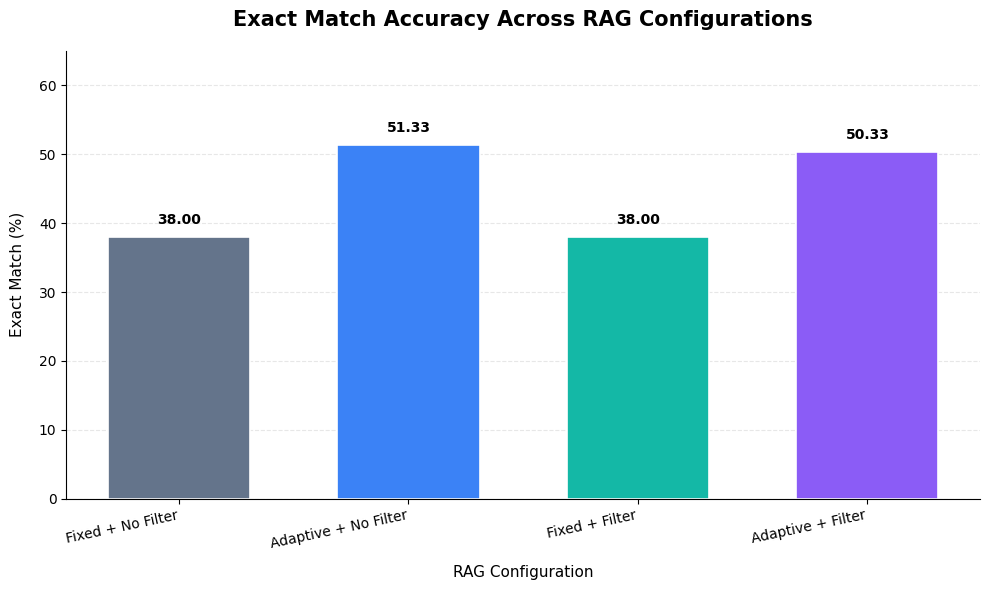

Saved: accuracy_comparison.png


In [52]:
# Cell 51: Professional chart setup + Exact Match

import matplotlib.pyplot as plt
import numpy as np

pipeline_order = [
    "Fixed + No Filter",
    "Adaptive + No Filter",
    "Fixed + Filter",
    "Adaptive + Filter"
]

plot_data = (
    summary.set_index("Pipeline")
    .reindex(pipeline_order)
    .reset_index()
)

# Consistent colors for all charts
chart_colors = ["#64748b", "#3b82f6", "#14b8a6", "#8b5cf6"]


def professional_bar_chart(
    column,
    title,
    ylabel,
    filename,
    value_format=".2f",
    ylim=None
):
    values = plot_data[column].astype(float).values

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.bar(
        plot_data["Pipeline"],
        values,
        color=chart_colors,
        width=0.62,
        edgecolor="white",
        linewidth=1.2
    )

    # Add exact numerical values above each bar
    for bar, value in zip(bars, values):
        ax.annotate(
            format(value, value_format),
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=18)
    ax.set_xlabel("RAG Configuration", fontsize=11, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=11, labelpad=10)

    ax.set_xticks(range(len(plot_data)))
    ax.set_xticklabels(
        plot_data["Pipeline"],
        rotation=12,
        ha="right"
    )

    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if ylim:
        ax.set_ylim(*ylim)
    else:
        ax.set_ylim(0, max(values) * 1.18)

    plt.tight_layout()

    # Save a high-resolution image for your research paper
    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close()

    print(f"Saved: {filename}")


# Exact Match chart
professional_bar_chart(
    column="Exact Match (%)",
    title="Exact Match Accuracy Across RAG Configurations",
    ylabel="Exact Match (%)",
    filename="accuracy_comparison.png",
    ylim=(0, 65)
)

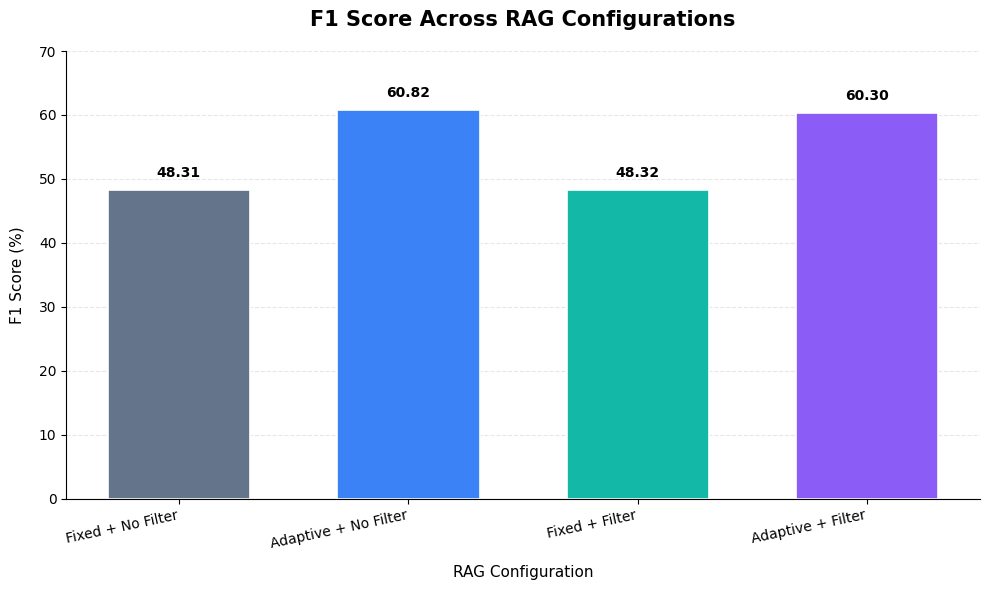

Saved: f1_comparison.png


In [53]:
# Cell 52: Professional F1 Score chart

professional_bar_chart(
    column="F1 (%)",
    title="F1 Score Across RAG Configurations",
    ylabel="F1 Score (%)",
    filename="f1_comparison.png",
    ylim=(0, 70)
)

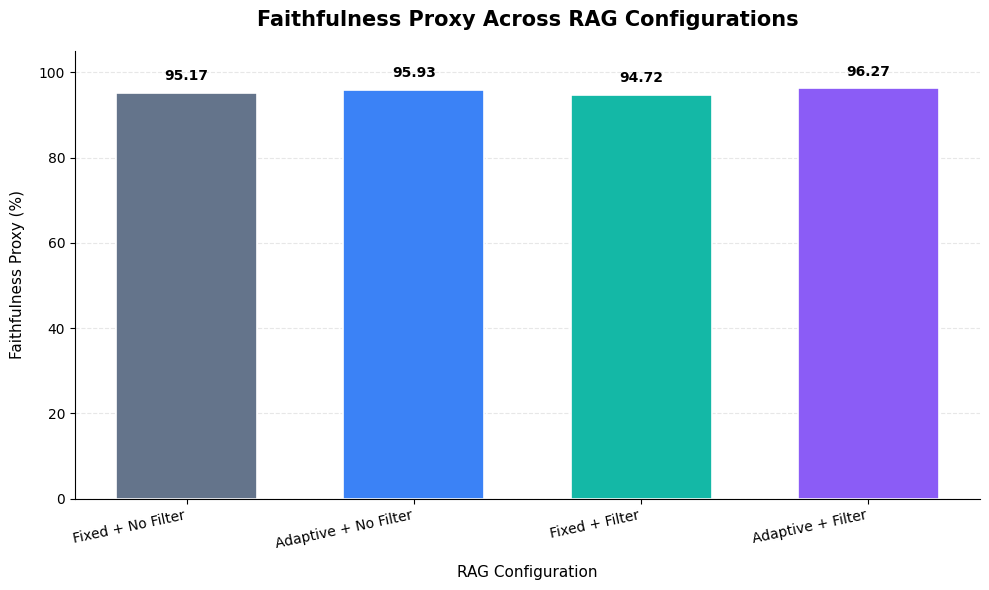

Saved: faithfulness_comparison.png


In [54]:
# Cell 53: Professional Faithfulness Proxy chart

professional_bar_chart(
    column="Faithfulness (%)",
    title="Faithfulness Proxy Across RAG Configurations",
    ylabel="Faithfulness Proxy (%)",
    filename="faithfulness_comparison.png",
    ylim=(0, 105)
)

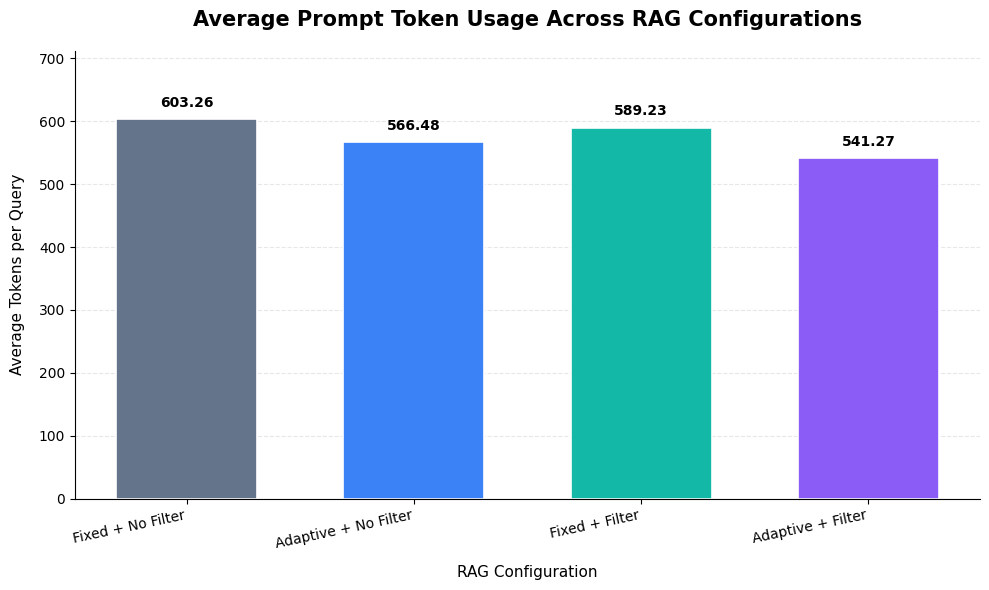

Saved: token_usage_comparison.png


In [55]:
# Cell 54: Professional Average Token Usage chart

professional_bar_chart(
    column="Avg Tokens / Query",
    title="Average Prompt Token Usage Across RAG Configurations",
    ylabel="Average Tokens per Query",
    filename="token_usage_comparison.png",
    value_format=".2f"
)

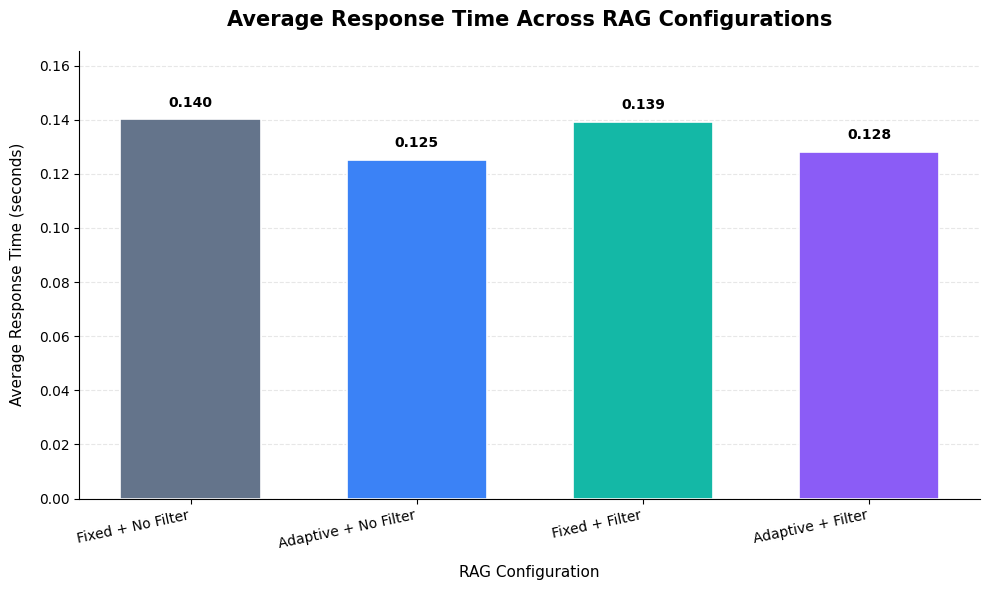

Saved: response_time_comparison.png


In [56]:
# Cell 55: Professional Response Time chart

professional_bar_chart(
    column="Avg Response Time (s)",
    title="Average Response Time Across RAG Configurations",
    ylabel="Average Response Time (seconds)",
    filename="response_time_comparison.png",
    value_format=".3f"
)

In [57]:
# Cell 56: Deltas vs baseline
baseline = summary[summary["Pipeline"] == "Fixed + No Filter"].iloc[0]
comparison = summary.copy()

comparison["Accuracy Change"] = comparison["Exact Match (%)"] - baseline["Exact Match (%)"]
comparison["F1 Change"] = comparison["F1 (%)"] - baseline["F1 (%)"]
comparison["Faithfulness Change"] = comparison["Faithfulness (%)"] - baseline["Faithfulness (%)"]
comparison["Token Change"] = comparison["Avg Tokens / Query"] - baseline["Avg Tokens / Query"]
comparison["Latency Change"] = comparison["Avg Response Time (s)"] - baseline["Avg Response Time (s)"]

display(comparison)

,Pipeline,Exact Match (%),F1 (%),Faithfulness (%),Retrieval Hit (%),Avg Tokens / Query,Avg Response Time (s),Avg Final Chunks,Accuracy Change,F1 Change,Faithfulness Change,Token Change,Latency Change
0,Adaptive + Filter,50.333333,60.302389,96.267677,83.666667,541.270000,0.128092,4.743333,12.333333,11.994688,1.101010,-61.986667,-0.012067
1,Adaptive + No Filter,51.333333,60.816105,95.934343,83.666667,566.476667,0.125162,5.000000,13.333333,12.508404,0.767677,-36.780000,-0.014997
2,Fixed + Filter,38.000000,48.316105,94.722222,80.333333,589.230000,0.139307,4.810000,0.000000,0.008403,-0.444444,-14.026667,-0.000852
3,Fixed + No Filter,38.000000,48.307701,95.166667,80.333333,603.256667,0.140159,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [58]:
# Cell 57: Final report
print("=" * 70)
print("RAG EXPERIMENT REPORT")
print("=" * 70)
print(f"Dataset: {CONFIG['dataset']}")
print(f"Embedding: {CONFIG['embedding_model']}")
print(f"LLM: {CONFIG['llm']}")
print(f"Top-k: {CONFIG['top_k']}")
print(f"Filter threshold: {CONFIG['filter_threshold']}")
print("=" * 70)

for _, row in summary.iterrows():
    print(f"\nPipeline: {row['Pipeline']}")
    print(f"  Exact Match: {row['Exact Match (%)']:.2f}%")
    print(f"  F1: {row['F1 (%)']:.2f}%")
    print(f"  Faithfulness: {row['Faithfulness (%)']:.2f}%")
    print(f"  Retrieval Hit: {row['Retrieval Hit (%)']:.2f}%")
    print(f"  Avg Tokens: {row['Avg Tokens / Query']:.2f}")
    print(f"  Avg Response Time: {row['Avg Response Time (s)']:.3f}s")

RAG EXPERIMENT REPORT
Dataset: squad
Embedding: sentence-transformers/all-MiniLM-L6-v2
LLM: google/flan-t5-small
Top-k: 5
Filter threshold: 0.35

Pipeline: Adaptive + Filter
  Exact Match: 50.33%
  F1: 60.30%
  Faithfulness: 96.27%
  Retrieval Hit: 83.67%
  Avg Tokens: 541.27
  Avg Response Time: 0.128s

Pipeline: Adaptive + No Filter
  Exact Match: 51.33%
  F1: 60.82%
  Faithfulness: 95.93%
  Retrieval Hit: 83.67%
  Avg Tokens: 566.48
  Avg Response Time: 0.125s

Pipeline: Fixed + Filter
  Exact Match: 38.00%
  F1: 48.32%
  Faithfulness: 94.72%
  Retrieval Hit: 80.33%
  Avg Tokens: 589.23
  Avg Response Time: 0.139s

Pipeline: Fixed + No Filter
  Exact Match: 38.00%
  F1: 48.31%
  Faithfulness: 95.17%
  Retrieval Hit: 80.33%
  Avg Tokens: 603.26
  Avg Response Time: 0.140s
